### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?
2. **Visualizations**:
    
    - Display the distribution of products across different categories using a bar chart. _If you face problems understanding the chart, do it for a subset of top categories._
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [65]:
df = pd.read_csv("../amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df["category"].value_counts().head()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [18]:
freq_table = pd.crosstab(index = df["category"],
                       columns = "count").sort_values(by = "count", ascending = False).head()
freq_table

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


In [22]:
freq_table.index

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts'],
      dtype='str', name='category')

In [23]:
freq_table.values

array([[836265],
       [ 19312],
       [ 19229],
       [ 19092],
       [ 18978]])

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

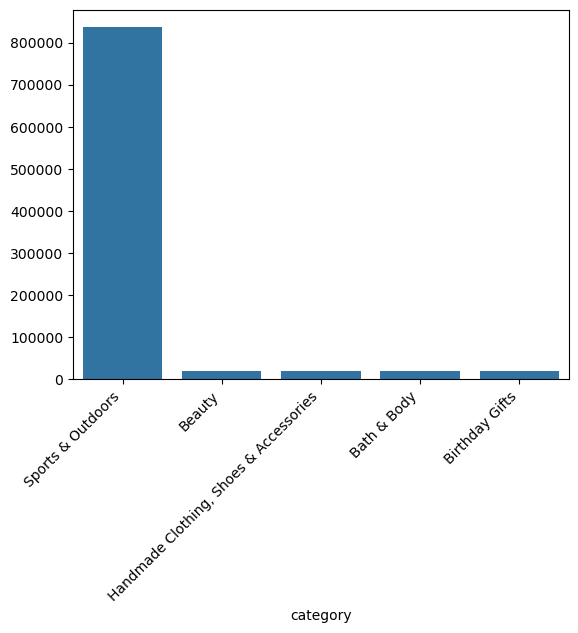

In [32]:
sns.barplot(x = freq_table.index, y = freq_table["count"].values)
plt.xticks(rotation=45, ha="right")

# i think this is not 

<Axes: >

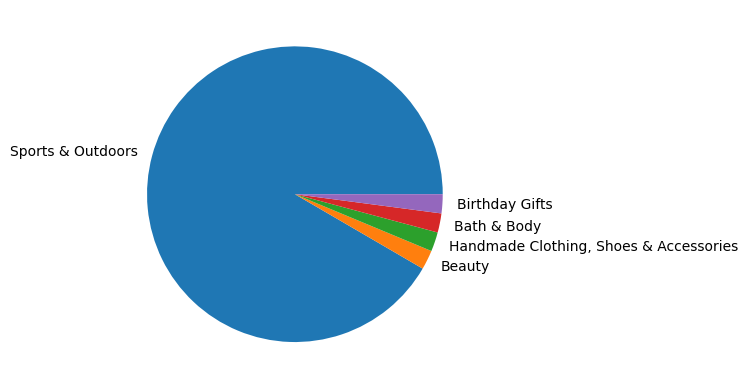

In [42]:
df["category"].value_counts().head().plot.pie()

# Sports&Outdoors dominates the list

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?
2. **Measures of Dispersion**:
    
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?
3. **Visualizations**:
    
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. _If its hard to read these diagrams, think why this is, and explain how it could be solved._.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [48]:
print("Mean: ", df["price"].mean())
print("Median: ", df["price"].median())
print("Mode: ", df["price"].mode())

#there is a big difference between the three measurements. 
# the mean, compared with the other two, indicates that there are some products that will be far more expensive than the median or the mode.
# and the mean and mode being lower than the median shows that there is a positive skew in the distribution.

Mean:  89.24380943923661
Median:  19.09
Mode:  0    9.99
Name: price, dtype: float64


In [50]:
round(df["price"].describe(), 2)
# i could do this to have all the info about the measures of dispersion

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [60]:
print("Variance: ", df["price"].var())
print("Standard Deviation: ", df["price"].std())
print("Range: ", df["price"].max() - df["price"].min())
print ("IQR:", df["price"].quantile(0.75) - df["price"].quantile(0.25))

# the max and min must be outliers as I don't know if there are free products in Amazon and products worth 100k
# the std deviation indicates that there is really dispersed and with a lot of positive skew. 

Variance:  119445.4853225653
Standard Deviation:  345.6088617535223
Range:  100000.0
IQR: 36.0


<Axes: xlabel='price', ylabel='Count'>

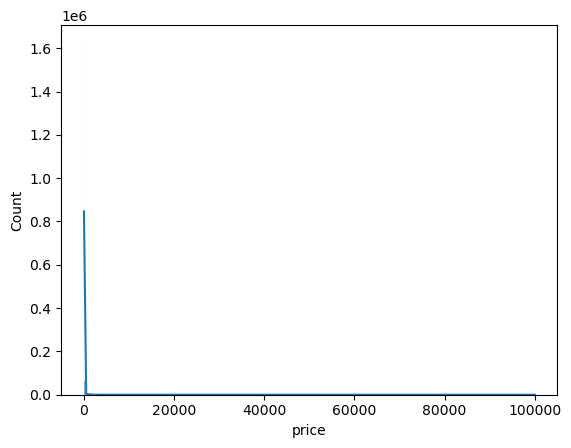

In [77]:
sns.histplot(df["price"], kde = True)
# when there are so many products and such a long range it is impossible to see anything

In [71]:
mask = df["price"] < df["price"].quantile(0.75)
# I filtered the dataset because it was impossible to understand anything before.

<Axes: xlabel='price', ylabel='Count'>

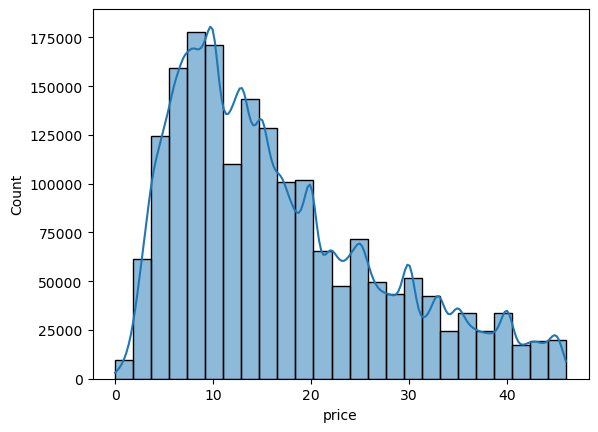

In [78]:
sns.histplot(df[mask]["price"], kde = True, bins = 25)
#most products are below 12€
# there is a weird drop around 12-14€
# the more expensive the less products there are

<Axes: ylabel='price'>

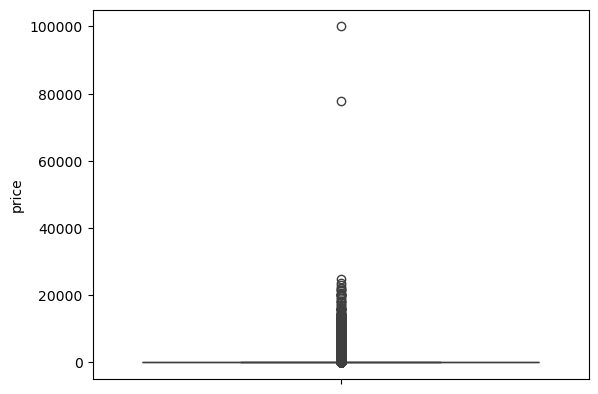

In [68]:
sns.boxplot(data = df["price"])

# in the boxplot everything looks like an outlier.
# you cannot even see the IQR and whiskers properly

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?
2. **Measures of Dispersion**:
    
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?
3. **Shape of the Distribution**:
    
    - Calculate the skewness and kurtosis for the `rating` column.
    - Are the ratings normally distributed, or do they lean towards higher or lower values?
4. **Visualizations**:
    
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [81]:
print("Mean: ", df["stars"].mean())
print("Median: ", df["stars"].median())
print("Mode: ", df["stars"].mode())

# I guess most customers don't rate the products, that's why the median and mode are 0. 
# the mean takes into account the 0 ratings so the rating is low.

Mean:  2.152836472966066
Median:  0.0
Mode:  0    0.0
Name: stars, dtype: float64


In [86]:
print("Variance: ", df["stars"].var())
print("Standard Deviation: ", df["stars"].std())
print ("IQR:", df["stars"].quantile(0.75) - df["stars"].quantile(0.25))

# the ratings are spread all over the 0-5 range of the ratings. 

Variance:  4.81743402976196
Standard Deviation:  2.1948653785054697
IQR: 4.4


In [88]:
print("Skew: ", df["stars"].skew())
print("Kurtosis: ", df["stars"].kurtosis())

#they lean towards lower values

Skew:  0.08120735761080881
Kurtosis:  -1.9260061280432994


<Axes: xlabel='stars', ylabel='Count'>

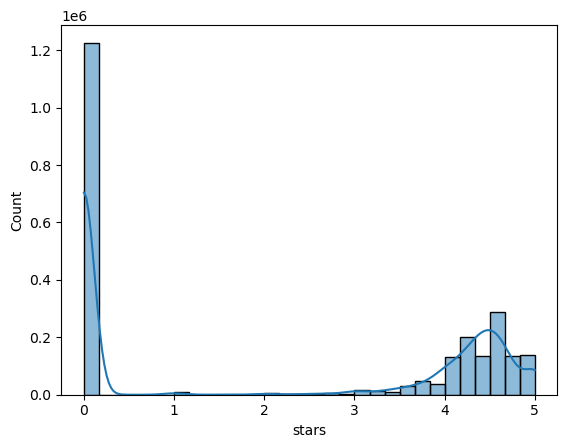

In [93]:
sns.histplot(data = df["stars"], kde = True, bins = 30)

# there is a high concentration of 0s